# Story 2: the IV

Step 3 of the analysis plan ([`final-analysis-plan.md`](../../docs/analysis/final-analysis-plan.md) §5). **Question:** can the mining instrument identify the
effect of lights on night LST, and what does its null rule out?

| Order | Notebook | Question |
|---|---|---|
| 1 | `01_pre_analysis.ipynb` | What do the stories rely on? No outcome-on-treatment regressions. |
| 2 | `02_baseline.ipynb` | Story 1: is the lights–night-LST association robust enough to be worth explaining? |
| 3 | `03_iv.ipynb`, `03b_iv_robustness.ipynb` | Story 2: can the mining instrument identify the effect, and what does its null rule out? |
| 4 | `04_channels.ipynb` | Story 3: which mechanisms could produce the association? |

| Block | Content | ◇ Rule (plan §5) |
|---|---|---|
| I1 | first stage, reduced form, 2SLS, 3×3 disc 2SLS, Anderson–Rubin CI | (P4: F < 10 → AR only) |
| I2 | MDE, IV − TWFE gap, scale of lights changes | AR CI contains the TWFE → the IV cannot speak to it |
| I3 | the bound against observed 2002–22 warming | later |
| I4 | donut: cells with no active mine within 10 km, vs the footprint cells | AR CI excludes 0 → unmasked · opposite RF signs → bound from the donut · bounded AR CI containing 0 → bound confirmed |
| I5 | radii 10 / 20 / 50 km and over-ID, with AR CIs | bound of record stays at 20 km; radii reported, not selected |

What the story can deliver is an **upper bound**, not a test of the TWFE-sized effect. The IV's
robustness (R1–R9) is in `03b_iv_robustness.ipynb`.

Split from `02_core_analysis.ipynb` on 2026-09-30 and re-run on 2026-09-30 with I4 and I5 added (same rows and specification as the 2026-09-29 core run, SLURM job 24273525). The I4–I5 rules were written in the plan before either block ran.

In [1]:
import sys
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from src.analysis.spec import (   # the fixed specification (plan §2)
    PANEL, NTL_HI, COV_MIN, Y, Y_DAY, XLOG, Z, M, FE, FE_CTY, BASE,
    build_panel, fit, row, reg_table, first_stage_F,
    anderson_rubin_ci, coefplot, forest,
)

build_panel()                     # cached: <data>/_analysis_panel_10km_v2.parquet
P = f"read_parquet('{PANEL}')"  # for DuckDB queries on the panel
sql = lambda q: duckdb.sql(q).df()

## The TWFE the IV is compared with

B1 in `02_baseline.ipynb` (the full OLS ladder is there).

In [2]:
m_twfe = fit(f"{Y} ~ {XLOG} | {FE}")
reg_table([m_twfe], ["TWFE (ctry x biome x yr)"], XLOG)

,estimate,std_error,p
spec,,,
TWFE (ctry x biome x yr),-0.03,0.0056,0.0


## I1. The mining IV

First stage, reduced form, 2SLS, and the 3×3 disc 2SLS (lights averaged over the cell and its 8
neighbours). With one instrument, 2SLS = RF / FS, so the reduced form is the evidence.

The **Anderson–Rubin CI** is robust to weak instruments. It is the set of b for which the
reduced form of (Y − b·X) on Z is insignificant. That coefficient is RF − b·FS, and its
cluster-robust variance is exactly quadratic in b. So three reduced forms give the set exactly:
of Y, of Y − X (`ar_m1`) and of Y + X (`ar_p1`). The `check` value is the `ar_m1` coefficient
minus (RF − FS), and should be ~0.

In [3]:
fs      = fit(f"{XLOG} ~ {Z} | {FE}")
rf      = fit(f"{Y} ~ {Z} | {FE}")
m_iv    = fit(f"{Y} ~ 1 | {FE} | ({XLOG} ~ {Z})")
iv_disc = fit(f"{Y} ~ 1 | {FE} | (log_ntl_disc1 ~ {Z})", subset="log_ntl_disc1 IS NOT NULL")
rf_m1   = fit(f"ar_m1 ~ {Z} | {FE}")
rf_p1   = fit(f"ar_p1 ~ {Z} | {FE}")

ar_lo, ar_hi, ar_kind, ar_check = anderson_rubin_ci(rf, fs, rf_m1, rf_p1)
iv = row(m_iv, XLOG)
f = row(fs, Z)
print(f"first stage {f['est']:.4f} ({f['se']:.4f}), F = {(f['est'] / f['se']) ** 2:.1f}")
print(f"2SLS {iv['est']:+.4f} ({iv['se']:.4f})   Wald 95% CI [{iv['lo']:+.3f}, {iv['hi']:+.3f}]")
print(f"AR 95% set: {ar_kind} [{ar_lo:+.3f}, {ar_hi:+.3f}]   (check {ar_check:+.2e})")
pd.concat([reg_table([fs], ["first stage"], Z), reg_table([rf], ["reduced form (night LST)"], Z),
           reg_table([m_iv], ["2SLS own cell"], XLOG), reg_table([iv_disc], ["2SLS 3x3 disc"], "log_ntl_disc1")])

first stage 0.0642 (0.0076), F = 71.0
2SLS -0.0259 (0.1503)   Wald 95% CI [-0.321, +0.269]
AR 95% set: bounded [-0.322, +0.284]   (check +4.17e-11)


,estimate,std_error,p
spec,,,
first stage,0.0642,0.0076,0.0000
reduced form (night LST),-0.0017,0.0097,0.8633
2SLS own cell,-0.0259,0.1503,0.8630
2SLS 3x3 disc,-0.0300,0.1737,0.8629


**Result.** First stage 0.0642 (0.0076), F = 71. The reduced form of night LST on mines is
−0.0017 (0.0097), p = 0.86. **2SLS −0.026 (0.150)**, Wald 95 % CI [−0.321, +0.269];
**AR 95 % set [−0.322, +0.284]**, bounded (check 1e-12). The 3×3 disc 2SLS is −0.030 (0.174).

**Interpretation.** With F = 71, the AR set and the Wald CI almost coincide, so weak-instrument
inference changes nothing here. The reduced form is a precise zero in its own units: a mine
within 20 km moves night LST by no more than about 0.02 K either way (95 %). But the first stage is small,
so dividing by 0.064 inflates that into a wide interval for β. The disc version, which lets the
effect spread over the neighbouring cells, gives the same picture.

## I2. What the null rules out

- The **minimum detectable effect** at 80 % power and 5 % size is 2.8 × SE.
- The **IV − TWFE gap** in units of the 2SLS SE says whether the IV contradicts the TWFE
  association or is merely silent about it.
- The **scale** of lights changes makes both concrete. It is the within-pixel change in
  `log1p(ntl_harm)` from 2002 to 2022, and the temperature change each estimate implies at it.

◇ If the AR set contains the TWFE estimate, the IV says nothing about whether the TWFE
association is causal. "The IV is insignificant" then counts only against effects outside the AR set.

In [4]:
b_ols = row(m_twfe, XLOG)["est"]
mde = 2.8 * iv["se"]
print(f"TWFE {b_ols:+.4f} | 2SLS {iv['est']:+.4f} (SE {iv['se']:.4f}) | MDE (80% power) {mde:.3f} K per log point")
print(f"IV - TWFE gap = {(iv['est'] - b_ols) / iv['se']:+.2f} SE of the 2SLS | MDE / |TWFE| = {mde / abs(b_ols):.0f}x")
print(f"AR set contains the TWFE estimate: {ar_lo <= b_ols <= ar_hi}")

dq = sql(f"""
    WITH d AS (
      SELECT pixel_id,
             max(CASE WHEN year = 2022 THEN {XLOG} END) - max(CASE WHEN year = 2002 THEN {XLOG} END) AS d,
             max(ntl_harm) AS ntl_max
      FROM {P} WHERE {BASE} GROUP BY pixel_id)
    SELECT 'all pixels' AS pixels, count(*) AS n, quantile_cont(d, 0.5) AS p50, quantile_cont(d, 0.9) AS p90,
           quantile_cont(d, 0.99) AS p99 FROM d WHERE d IS NOT NULL
    UNION ALL
    SELECT 'ever lit (ntl_harm > 0)', count(*), quantile_cont(d, 0.5), quantile_cont(d, 0.9),
           quantile_cont(d, 0.99) FROM d WHERE d IS NOT NULL AND ntl_max > 0""").set_index("pixels")
display(dq.round(3))
q = dq.loc["ever lit (ntl_harm > 0)", ["p50", "p90", "p99"]]
pd.DataFrame({"TWFE": b_ols * q, "2SLS": iv["est"] * q, "AR lower": ar_lo * q, "AR upper": ar_hi * q,
              "MDE": mde * q}).T.round(3).rename(columns=lambda c: f"K at {c} of ΔNTL (ever lit)")

TWFE -0.0300 | 2SLS -0.0259 (SE 0.1503) | MDE (80% power) 0.421 K per log point
IV - TWFE gap = +0.03 SE of the 2SLS | MDE / |TWFE| = 14x
AR set contains the TWFE estimate: True


,n,p50,p90,p99
pixels,,,,
all pixels,1199373,0.000,1.058,2.420
ever lit (ntl_harm > 0),720109,0.182,1.424,2.616


,K at p50 of ΔNTL (ever lit),K at p90 of ΔNTL (ever lit),K at p99 of ΔNTL (ever lit)
TWFE,-0.005,-0.043,-0.079
2SLS,-0.005,-0.037,-0.068
AR lower,-0.059,-0.459,-0.844
AR upper,0.052,0.404,0.742
MDE,0.077,0.600,1.101


**Result.** TWFE −0.030 vs 2SLS −0.026 (SE 0.150). The gap is **+0.03 SE**. **MDE = 0.42 K per
log point, 14× |TWFE|.** ◇ The AR set [−0.32, +0.28] contains the TWFE estimate.

Within-pixel change in `log1p(ntl_harm)` 2002 → 2022 among ever-lit pixels (720 k): p50 0.18,
p90 1.42, p99 2.62. What each estimate implies for night LST at that change:

| | p50 | p90 | p99 |
|---|---:|---:|---:|
| TWFE | −0.005 K | −0.043 K | −0.079 K |
| 2SLS | −0.005 K | −0.037 K | −0.068 K |
| AR lower / upper | −0.06 / +0.05 K | −0.46 / +0.40 K | −0.84 / +0.74 K |
| MDE | 0.08 K | 0.60 K | 1.10 K |

**Interpretation.** ◇ **The IV says nothing about whether the TWFE association is causal.** The
2SLS point estimate sits on the TWFE, and the IV would need an effect 14× larger to detect one
with 80 % power. What the null does rule out is large effects: beyond about ±0.3 K per log point,
i.e. more than about 0.4 K of warming or cooling at 90th-percentile lights growth over two
decades. "The mining IV is insignificant" is therefore not evidence against the TWFE
coefficient. It is evidence that this instrument cannot resolve effects of that size.

## I4. Donut: is the null masked by the mines' own footprint?

If mines also heat or cool nearby cells directly (bare ground, clearing, dust), that direct
effect can cancel a lights effect in the reduced form. The donut drops every cell with an active
mine within 10 km in any year (`max(mine_count_10km) = 0` over 2002–22; the count is averaged
over the cell's 1 km pixel centres, so zero means no mine within 10 km of any part of the cell).
The instrument stays `mine_count_20km`, so in the donut only mines 10–20 km away enter.

- **D (donut):** cells with no active mine within 10 km in any year.
- **F (footprint):** the complement.

First stage, reduced form, 2SLS and AR CI for night LST; reduced form and 2SLS for day LST (the
AR helper needs the night-LST AR columns).

◇ Rules (plan §5): F < 10 in D → AR only · D's AR CI excludes 0 → **unmasked**, D becomes the
Story 2 estimate · reduced forms in D and F of opposite sign (both p < 0.10) → **direct mine
effect**, the bound is taken from D · D's AR CI bounded and containing 0 → **bound confirmed**
without the footprint cells.

In [5]:
DONUT_IDS = f"SELECT pixel_id FROM {P} GROUP BY pixel_id HAVING max(mine_count_10km) = 0"
SAMPLES = {"D donut": f"pixel_id IN ({DONUT_IDS})", "F footprint": f"pixel_id NOT IN ({DONUT_IDS})"}
DAY = f"{Y_DAY} IS NOT NULL"


def ar_excludes_zero(lo, hi, kind):
    return (kind == "bounded" and (lo > 0 or hi < 0)) or (kind == "union of two rays" and lo < 0 < hi)


def iv_block(instr=Z, subset=None, day=True):
    s = subset
    out = dict(fs=fit(f"{XLOG} ~ {instr} | {FE}", subset=s), rf=fit(f"{Y} ~ {instr} | {FE}", subset=s),
               iv=fit(f"{Y} ~ 1 | {FE} | ({XLOG} ~ {instr})", subset=s),
               rf_m1=fit(f"ar_m1 ~ {instr} | {FE}", subset=s), rf_p1=fit(f"ar_p1 ~ {instr} | {FE}", subset=s))
    if day:
        sd = " AND ".join(filter(None, [DAY, s]))
        out |= dict(rf_day=fit(f"{Y_DAY} ~ {instr} | {FE}", subset=sd),
                    iv_day=fit(f"{Y_DAY} ~ 1 | {FE} | ({XLOG} ~ {instr})", subset=sd))
    f, r, v = row(out["fs"], instr), row(out["rf"], instr), row(out["iv"], XLOG)
    lo, hi, kind, _ = anderson_rubin_ci(out["rf"], out["fs"], out["rf_m1"], out["rf_p1"], instr=instr)
    res = {"first stage": f["est"], "fs se": f["se"], "F": (f["est"] / f["se"]) ** 2,
           "RF night": r["est"], "RF se": r["se"], "RF p": r["p"],
           "2SLS night": v["est"], "2SLS se": v["se"], "AR lo": lo, "AR hi": hi, "AR kind": kind}
    if day:
        rd, vd = row(out["rf_day"], instr), row(out["iv_day"], XLOG)
        res |= {"RF day": rd["est"], "RF day p": rd["p"], "2SLS day": vd["est"], "2SLS day se": vd["se"]}
    return out, res


i4 = {k: iv_block(subset=s) for k, s in SAMPLES.items()}
sizes = {k: sql(f"SELECT count(*) AS pixel_years, count(DISTINCT pixel_id) AS pixels, "
                f"avg((mine_count_20km > 0)::INT) AS share_exposed FROM {P} WHERE {BASE} AND {s}").iloc[0]
         for k, s in SAMPLES.items()}
i4_tab = pd.DataFrame({k: {**sizes[k].to_dict(), **r} for k, (_, r) in i4.items()})
Dr, Fr = i4["D donut"][1], i4["F footprint"][1]
print(f"I4 rule: donut first-stage F = {Dr['F']:.1f} -> {'AR only' if Dr['F'] < 10 else 'Wald and AR'}")
print(f"I4 rule: donut AR CI {Dr['AR kind']} [{Dr['AR lo']:+.3f}, {Dr['AR hi']:+.3f}] excludes 0 -> "
      f"{'UNMASKED' if ar_excludes_zero(Dr['AR lo'], Dr['AR hi'], Dr['AR kind']) else 'no'}")
opp = Dr["RF p"] < 0.10 and Fr["RF p"] < 0.10 and np.sign(Dr["RF night"]) != np.sign(Fr["RF night"])
print(f"I4 rule: reduced forms of opposite sign in D and F (both p < 0.10) -> {'DIRECT MINE EFFECT' if opp else 'no'}")
conf = Dr["AR kind"] == "bounded" and Dr["AR lo"] <= 0 <= Dr["AR hi"]
print(f"I4 rule: donut AR CI bounded and containing 0 -> {'BOUND CONFIRMED without footprint cells' if conf else 'no'}")
i4_tab

I4 rule: donut first-stage F = 11.6 -> Wald and AR
I4 rule: donut AR CI bounded [-2.167, +0.185] excludes 0 -> no
I4 rule: reduced forms of opposite sign in D and F (both p < 0.10) -> no
I4 rule: donut AR CI bounded and containing 0 -> BOUND CONFIRMED without footprint cells


,D donut,F footprint
pixel_years,24300076.0,833688.0
pixels,1165526.0,39954.0
share_exposed,0.031526,0.819488
first stage,0.028657,0.051259
fs se,0.008408,0.006184
F,11.616243,68.703132
RF night,-0.022627,0.001745
RF se,0.013813,0.007073
RF p,0.101398,0.805075
2SLS night,-0.789523,0.034051


**Result.** The donut keeps 97 % of the pixels but only 3 % of them have a mine within 20 km;
its first stage is weak but usable (F = 11.6). Its reduced form is **−0.023 (0.014), p = 0.10**,
2SLS −0.79 (0.48), **AR 95 % set [−2.17, +0.19]**. The footprint cells (40,000 pixels, 82 %
exposed) carry the I1 identification: F = 69, reduced form +0.002 (0.007), 2SLS +0.03 (0.14), AR
[−0.24, +0.32]. Day LST moves in neither sample.

◇ The donut AR set contains 0 → not unmasked. ◇ The reduced forms differ in sign, but only the
donut's comes near p = 0.10 → no direct mine effect by the rule. ◇ The donut AR set is bounded and
contains 0 → **bound confirmed without the footprint cells**.

Reading: nothing is masked. The I1 bound comes from the footprint cells, and dropping them
leaves a set seven times wider. The donut's negative point estimate has the TWFE sign but is
not evidence: its set runs from −2.2 to +0.2 K per log point.

## I5. Radius comparison (pre-specified)

Mines within 10, 20 and 50 km, and the over-identified count + price shock. The 20 km row is I1.
The over-identified 2SLS is reported with its Wald CI only (the AR helper covers one instrument).

◇ Rules (plan §5): the bound of record stays at 20 km, chosen on the P4 π profile before these
results; the other radii are reported, not selected, and 10 km is read together with I4 (it is
the most exposed to footprint physics) · AR CIs of different radii that do not overlap → the
estimand depends on distance, and the bound is reported per radius.

I5 rule: bound of record = 20 km AR CI [-0.322, +0.284]
I5 rule: radii with non-overlapping AR CIs -> none


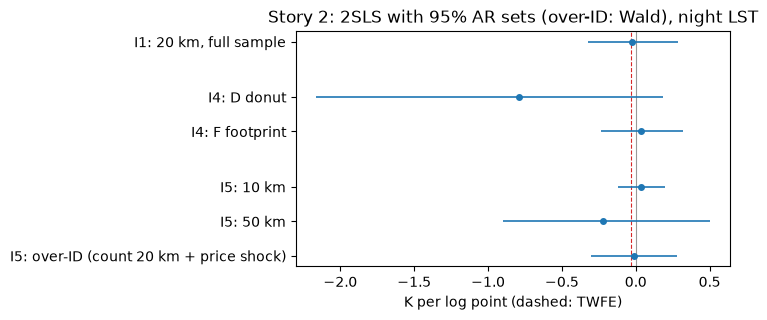

,10 km,20 km (I1),50 km,over-ID (count 20 km + price shock)
first stage,0.184364,0.064232,0.01604,NaN
fs se,0.015616,0.007625,0.003428,NaN
F,139.383762,70.953228,21.897304,NaN
RF night,0.006128,-0.001666,-0.003504,NaN
RF se,0.014747,0.009675,0.005318,NaN
RF p,0.677747,0.863304,0.509952,NaN
2SLS night,0.033237,-0.025934,-0.218467,-0.014389
2SLS se,0.080232,0.150324,0.325351,0.148597
AR lo,-0.12346,-0.322461,-0.900771,-0.305639
AR hi,0.195516,0.283567,0.504295,0.276861


In [6]:
i5 = {"10 km": iv_block("mine_count_10km", day=False), "50 km": iv_block("mine_count_50km", day=False)}
i5_res = {"10 km": i5["10 km"][1], "20 km (I1)": {
    "first stage": f["est"], "fs se": f["se"], "F": (f["est"] / f["se"]) ** 2,
    "RF night": row(rf, Z)["est"], "RF se": row(rf, Z)["se"], "RF p": row(rf, Z)["p"],
    "2SLS night": iv["est"], "2SLS se": iv["se"], "AR lo": ar_lo, "AR hi": ar_hi, "AR kind": ar_kind},
    "50 km": i5["50 km"][1]}
m_oi = fit(f"{Y} ~ 1 | {FE} | ({XLOG} ~ {Z} + mine_priceshock_20km)")
oi = row(m_oi, XLOG)
i5_res["over-ID (count 20 km + price shock)"] = {"2SLS night": oi["est"], "2SLS se": oi["se"],
                                                  "AR lo": oi["lo"], "AR hi": oi["hi"], "AR kind": "Wald CI"}
i5_tab = pd.DataFrame(i5_res)

bounded = {k: (r["AR lo"], r["AR hi"]) for k, r in i5_res.items() if r["AR kind"] == "bounded"}
pairs = [(a, b) for i, a in enumerate(bounded) for b in list(bounded)[i + 1:]
         if bounded[a][1] < bounded[b][0] or bounded[b][1] < bounded[a][0]]
print(f"I5 rule: bound of record = 20 km AR CI [{ar_lo:+.3f}, {ar_hi:+.3f}]")
print(f"I5 rule: radii with non-overlapping AR CIs -> {pairs or 'none'}")

rows = [dict(group="I1", label="20 km, full sample", est=iv["est"], lo=ar_lo, hi=ar_hi)]
rows += [dict(group="I4", label=k, est=r["2SLS night"], lo=r["AR lo"], hi=r["AR hi"])
         for k, (_, r) in i4.items() if r["AR kind"] == "bounded"]
rows += [dict(group="I5", label=k, est=r["2SLS night"], lo=r["AR lo"], hi=r["AR hi"])
         for k, r in i5_res.items() if k != "20 km (I1)" and r["AR kind"] in ("bounded", "Wald CI")]
forest(pd.DataFrame(rows), "Story 2: 2SLS with 95% AR sets (over-ID: Wald), night LST",
       ref=row(m_twfe, XLOG)["est"], xlabel="K per log point (dashed: TWFE)")
plt.show()
i5_tab

**Result.** The first stage decays with radius (F = 139 at 10 km, 71 at 20 km, 22 at 50 km).
The reduced form is null at every radius (p = 0.68, 0.86, 0.51). The AR sets are **[−0.12, +0.20]**
at 10 km, [−0.32, +0.28] at 20 km, [−0.90, +0.50] at 50 km. The over-identified 2SLS is −0.014
(0.149), Wald CI [−0.31, +0.28].

◇ All AR sets overlap → the estimand does not depend on distance. ◇ **The bound of record stays at
20 km: ±0.3 K per log point.** The 10 km set is half as wide, with MDE 2.8 × 0.080 = 0.22 K per log
point, still 7× the TWFE. It is reported, not selected: choosing the radius after seeing the sets
is the specification search the plan rules out. It shows that a closer radius gives more power
but does not bring the TWFE size within reach.

## Summary

| Block | Result | ◇ |
|---|---|---|
| I1 | F = 71; RF −0.002 (0.010); 2SLS −0.026 (0.150); AR [−0.32, +0.28] | Wald and AR agree |
| I2 | MDE 0.42 K per log point = 14× TWFE; gap 0.03 SE | **AR set contains the TWFE: the IV cannot speak to it** |
| I4 | Donut F = 11.6, RF −0.023 (p = 0.10), AR [−2.17, +0.19]; footprint F = 69, AR [−0.24, +0.32] | **bound confirmed; nothing masked** |
| I5 | AR 10 km [−0.12, +0.20], 20 km [−0.32, +0.28], 50 km [−0.90, +0.50]; over-ID Wald [−0.31, +0.28] | sets overlap; **bound of record stays at 20 km** |

"The mining IV is null" holds as a statement about significance, not as evidence against the
TWFE association: the IV is centred on it, and its SE is 27× the TWFE one. What the story
delivers is an **upper bound**: effects beyond about ±0.3 K per log point, about ±0.4 K at p90
lights growth over 2002–22, are ruled out for mine-proximate compliers. A new instrument would
need a first-stage F of about 14,000 to test an effect of the TWFE size (plan §5). Neither the
donut (I4) nor another radius (I5) changes this: the mines' own footprint does not mask an
effect, and the tightest pre-specified set (10 km, ±0.2 K) is still 7× the TWFE in MDE terms.